# 05 - Hyperparameter Tuning & Final Evaluation
1. Read the candidates from `reports/model_comparison.csv` (notebook 04).
2. `GridSearchCV` on each candidate, with the **same CV** as notebook 04 (`TimeSeriesSplit(5)` on the same 30k training sample).
3. Pick the winner by **CV RMSE only**.
4. Refit the winner on the full training set, evaluate it **once** on the test set, and save the whole Pipeline.

In [1]:
# --- Project setup (works locally and on Colab after cloning the repo) ---
import os, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: D:\ML


In [2]:
import json
import time
import warnings
import joblib
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score

from src.preprocessing import make_preprocessor
from src.modeling import load_split, cv_sample, make_cv, RANDOM_STATE

warnings.filterwarnings("ignore", category=UserWarning)

X_train, X_test, y_train, y_test = load_split()
X_cv, y_cv = cv_sample(X_train, y_train)
print(X_train.shape, X_test.shape, X_cv.shape)

(245801, 14) (61451, 14) (30000, 14)


## Candidates from notebook 04

In [3]:
comparison = pd.read_csv("reports/model_comparison.csv")
display(comparison[["Model", "Mean RMSE", "Std RMSE", "Mean R2"]].round(5))

candidates = comparison.loc[~comparison["Model"].str.startswith("Baseline"), "Model"].tolist()
print("Models selected for tuning:", candidates)

,Model,Mean RMSE,Std RMSE,Mean R2
0,Lasso,0.13212,0.00652,0.02261
1,Baseline (predict mean),0.13366,0.00652,-0.00033
2,LightGBM (bonus),0.13401,0.00758,-0.00503
3,HistGradientBoosting (bonus),0.13413,0.00796,-0.00655
4,Ridge,0.13756,0.01635,-0.05938
5,Linear Regression,0.13778,0.01678,-0.06303
6,Random Forest,0.14355,0.00840,-0.15464
7,SVR,0.14435,0.00274,-0.17182
8,KNN,0.14681,0.00748,-0.20866
9,XGBoost (bonus),0.15307,0.01613,-0.30995


Models selected for tuning: ['Lasso', 'LightGBM (bonus)', 'HistGradientBoosting (bonus)', 'Ridge', 'Linear Regression', 'Random Forest', 'SVR', 'KNN', 'XGBoost (bonus)', 'Linear Regression (Gradient Descent)', 'Decision Tree', 'ANN (MLP)', 'Polynomial Regression (deg 2)']


**Why tune every model instead of only the top few?** With default settings, most models fit the noise
(fully grown trees, k=5 neighbours, unregularised polynomial terms), and only Lasso beats the baseline (plus ANN and SGD are unstable with defaults).
The default ranking therefore reflects default hyper-parameters rather than the algorithms themselves.
Tuning every model with regularising grids is cheap on the 30k sample and gives a fair final choice.

## Search spaces
`model__` prefixes each parameter because the estimator sits inside the Pipeline under the step name `model`.

In [4]:
from src.model_zoo import MODELS, SEARCH_SPACES
search_spaces = {name: (MODELS[name][2], SEARCH_SPACES[name]) for name in SEARCH_SPACES}
display(pd.DataFrame([(n, MODELS[n][0], len(pd.DataFrame(list(__import__("itertools").product(*g.values())))))
                      for n, g in SEARCH_SPACES.items()], columns=["Model", "Course group", "Combinations"]))

,Model,Course group,Combinations
0,Linear Regression,lecture,2
1,Linear Regression (Gradient Descent),lecture,12
2,Decision Tree,lecture,12
3,Random Forest,lecture,18
4,SVR,lecture,6
5,ANN (MLP),lecture,12
6,Ridge,extra,5
7,Lasso,extra,4
8,Polynomial Regression (deg 2),extra,4
9,KNN,extra,8


## GridSearchCV per candidate (training sample only)

In [5]:
grids, rows = {}, []
before = comparison.set_index("Model")

for name in candidates:
    estimator, param_grid = search_spaces[name]
    pipeline = Pipeline([("preprocessor", make_preprocessor(X_cv)), ("model", estimator)])
    grid = GridSearchCV(pipeline, param_grid, cv=make_cv(),
                        scoring="neg_root_mean_squared_error", n_jobs=-1, refit=True)
    start = time.time()
    grid.fit(X_cv, y_cv)
    grids[name] = grid
    std = grid.cv_results_["std_test_score"][grid.best_index_]
    rows.append({
        "Model": name,
        "Course group": MODELS[name][0],
        "Before RMSE": before.loc[name, "Mean RMSE"],
        "After RMSE": -grid.best_score_,
        "After RMSE std": std,
        "Improvement %": (1 - (-grid.best_score_) / before.loc[name, "Mean RMSE"]) * 100,
        "Before R2": before.loc[name, "Mean R2"],
        "Best Parameters": json.dumps({k.replace("model__", ""): v for k, v in grid.best_params_.items()}),
        "Combinations": len(grid.cv_results_["params"]),
        "Mean fit time (s)": grid.cv_results_["mean_fit_time"][grid.best_index_],
        **{f"Fold {k} RMSE": -grid.cv_results_[f"split{k}_test_score"][grid.best_index_] for k in range(5)},
        "Search time (s)": round(time.time() - start),
    })
    print(f"{name}: best CV RMSE {-grid.best_score_:.5f}  params {grid.best_params_}  ({time.time()-start:.0f}s)")

Lasso: best CV RMSE 0.13212  params {'model__alpha': 0.001}  (10s)


LightGBM (bonus): best CV RMSE 0.13200  params {'model__learning_rate': 0.03, 'model__min_child_samples': 200, 'model__n_estimators': 200, 'model__num_leaves': 15}  (25s)


HistGradientBoosting (bonus): best CV RMSE 0.13181  params {'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__max_iter': 200, 'model__min_samples_leaf': 200}  (29s)


Ridge: best CV RMSE 0.13286  params {'model__alpha': 1000}  (2s)


Linear Regression: best CV RMSE 0.13778  params {'model__fit_intercept': True}  (2s)


Random Forest: best CV RMSE 0.13168  params {'model__max_depth': 12, 'model__min_samples_leaf': 200, 'model__n_estimators': 100}  (312s)


... (3 outputs left out)

Linear Regression (Gradient Descent): best CV RMSE 0.13212  params {'model__alpha': 0.001, 'model__learning_rate': 'adaptive', 'model__penalty': 'l1'}  (8s)


Decision Tree: best CV RMSE 0.13195  params {'model__max_depth': 8, 'model__min_samples_leaf': 500}  (5s)


ANN (MLP): best CV RMSE 0.13366  params {'model__alpha': 100.0, 'model__hidden_layer_sizes': (64, 32), 'model__solver': 'sgd'}  (98s)


Polynomial Regression (deg 2): best CV RMSE 0.15995  params {'model__lin__alpha': 1000}  (14s)


In [6]:
tuning = pd.DataFrame(rows).sort_values("After RMSE").reset_index(drop=True)
# R2 of the best params, computed on the same folds
for i, r in tuning.iterrows():
    g = grids[r["Model"]]
    pipe = clone(g.best_estimator_)
    tuning.loc[i, "After R2"] = cross_val_score(pipe, X_cv, y_cv, cv=make_cv(), scoring="r2", n_jobs=-1).mean()
display(tuning.round(5))
tuning.to_csv("reports/tuning_comparison.csv", index=False)

,Model,Course group,Before RMSE,After RMSE,After RMSE std,Improvement %,Before R2,Best Parameters,Combinations,Mean fit time (s),Fold 0 RMSE,Fold 1 RMSE,Fold 2 RMSE,Fold 3 RMSE,Fold 4 RMSE,Search time (s),After R2
0,Random Forest,lecture,0.14355,0.13168,0.00659,8.26557,-0.15464,"{""max_depth"": 12, ""min_samples_leaf"": 200, ""n_...",18,15.09023,0.14203,0.13646,0.12931,0.12570,0.12492,312,0.02908
1,HistGradientBoosting (bonus),newer,0.13413,0.13181,0.00655,1.73292,-0.00655,"{""learning_rate"": 0.03, ""max_depth"": 3, ""max_i...",16,2.04178,0.14187,0.13679,0.12968,0.12580,0.12490,29,0.02725
2,XGBoost (bonus),newer,0.15307,0.13189,0.00648,13.83293,-0.30995,"{""learning_rate"": 0.03, ""max_depth"": 3, ""min_c...",24,1.53379,0.14195,0.13668,0.12974,0.12628,0.12481,51,0.02591
3,Decision Tree,lecture,0.21464,0.13195,0.00665,38.52611,-1.61260,"{""max_depth"": 8, ""min_samples_leaf"": 500}",12,0.46839,0.14258,0.13645,0.12952,0.12619,0.12499,5,0.02521
4,LightGBM (bonus),newer,0.13401,0.13200,0.00663,1.49937,-0.00503,"{""learning_rate"": 0.03, ""min_child_samples"": 2...",16,1.21236,0.14214,0.13714,0.12974,0.12620,0.12479,25,0.02437
5,Lasso,extra,0.13212,0.13212,0.00652,0.00000,0.02261,"{""alpha"": 0.001}",4,0.40909,0.14231,0.13684,0.12996,0.12626,0.12521,10,0.02261
6,Linear Regression (Gradient Descent),lecture,0.15398,0.13212,0.00653,14.19768,-0.39094,"{""alpha"": 0.001, ""learning_rate"": ""adaptive"", ...",12,1.04752,0.14233,0.13684,0.12997,0.12626,0.12521,8,0.02257
7,Ridge,extra,0.13756,0.13286,0.00772,3.41156,-0.05938,"{""alpha"": 1000}",5,0.29722,0.14590,0.13697,0.13006,0.12622,0.12517,2,0.01219
8,KNN,extra,0.14681,0.13314,0.00662,9.30577,-0.20866,"{""n_neighbors"": 100, ""weights"": ""uniform""}",8,0.26775,0.14348,0.13812,0.13049,0.12726,0.12637,23,0.00736
9,ANN (MLP),lecture,0.25888,0.13366,0.00653,48.36979,-3.45593,"{""alpha"": 100.0, ""hidden_layer_sizes"": [64, 32...",12,6.63958,0.14381,0.13836,0.13174,0.12786,0.12654,98,-0.00041


## Choose the final model - by CV RMSE only

**Selection rule.** The first version of this project selected **Random Forest** (lowest CV RMSE among the original
9 models). The models added later (ANN, gradient-descent linear regression, LightGBM, HistGradientBoosting) can only
replace it if they beat it by **more than one fold standard deviation** of CV RMSE. A smaller gap is a statistical tie,
and switching would not be justified. The decision uses CV only, never the test set.

In [7]:
PREVIOUS_WINNER = "Random Forest"
t = tuning.set_index("Model")
challenger = tuning.iloc[0]["Model"]
gap = t.loc[PREVIOUS_WINNER, "After RMSE"] - t.loc[challenger, "After RMSE"]
std = t.loc[challenger, "After RMSE std"]
if challenger != PREVIOUS_WINNER and gap > std:
    best_name = challenger
    print(f"{challenger} beats {PREVIOUS_WINNER} by {gap:.5f} > fold std {std:.5f} -> final model replaced")
else:
    best_name = PREVIOUS_WINNER
    print(f"Lowest CV RMSE: {challenger}. Gap to {PREVIOUS_WINNER}: {gap:.5f} <= fold std {std:.5f} "
          f"-> statistical tie, keep {PREVIOUS_WINNER}")
best_grid = grids[best_name]
print("Selected model:", best_name)
print("Best Parameters:", best_grid.best_params_)
print("Best CV RMSE:", -best_grid.best_score_)

Lowest CV RMSE: Random Forest. Gap to Random Forest: 0.00000 <= fold std 0.00659 -> statistical tie, keep Random Forest
Selected model: Random Forest
Best Parameters: {'model__max_depth': 12, 'model__min_samples_leaf': 200, 'model__n_estimators': 100}
Best CV RMSE: 0.13168300657459792


### Refit on the full training set
`grid.best_estimator_` was refit on the 30k sample. With the chosen parameters fixed, we refit the same Pipeline on
**all 245,801 training rows** so the final model uses all the training data. No test data is involved.
SVR is the one exception: it does not scale to 245k rows, so if it wins we keep the sample-fitted `best_estimator_`.

In [8]:
if best_name == "SVR":
    best_model = best_grid.best_estimator_
else:
    best_model = clone(best_grid.best_estimator_)
    best_model.set_params(preprocessor=make_preprocessor(X_train))
    start = time.time()
    best_model.fit(X_train, y_train)
    print(f"Refit on full train in {time.time()-start:.0f}s")
best_model

Refit on full train in 199s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['source','destination','name',...,'windSpeed','visibility','cloudCover']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This sub

## Final evaluation on the test set (final evaluation only)

In [9]:
y_pred = best_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("MAE:", mae)

MSE: 0.018289427755525847
RMSE: 0.1352384107993208
R2 Score: 0.0430374244956917
MAE: 0.0560873927777349


### Context for the numbers
- **Baseline:** always predict the training mean. Any useful model must beat it.
- **Surged rides only:** about 93% of rides are 1.0, so we also check the error where surge > 1.

In [10]:
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
b_pred = baseline.predict(X_test)

surged = y_test > 1
def metrics(y, p):
    return {"MSE": mean_squared_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)),
            "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p) if len(set(y)) > 1 else np.nan}

final = pd.DataFrame({
    f"{best_name} - all test rides": metrics(y_test, y_pred),
    "Baseline - all test rides": metrics(y_test, b_pred),
    f"{best_name} - surged rides only": metrics(y_test[surged], y_pred[surged]),
    "Baseline - surged rides only": metrics(y_test[surged], b_pred[surged]),
}).T
display(final.round(5))

print("Test rows:", len(y_test), "| surged:", int(surged.sum()))
print("Mean prediction on surged rides:", y_pred[surged].mean().round(4), "vs non-surged:", y_pred[~surged].mean().round(4))

,MSE,RMSE,MAE,R2
Random Forest - all test rides,0.01829,0.13524,0.05609,0.04304
Baseline - all test rides,0.01911,0.13825,0.05896,-0.00008
Random Forest - surged rides only,0.23977,0.48966,0.40875,-2.18903
Baseline - surged rides only,0.26100,0.51089,0.43107,-2.47150


Test rows: 61451 | surged: 4289
Mean prediction on surged rides: 1.0534 vs non-surged: 1.0296


In [11]:
test_view = X_test.assign(actual=y_test.values, predicted=y_pred)
by_product = test_view.groupby("name").agg(actual_mean=("actual", "mean"), predicted_mean=("predicted", "mean"),
                                           pct_surged=("actual", lambda s: (s > 1).mean() * 100))
display(by_product.round(4))

,actual_mean,predicted_mean,pct_surged
name,,,
Lux,1.0377,1.0376,8.1951
Lux Black,1.0384,1.0379,8.5396
Lux Black XL,1.0385,1.0375,8.5179
Lyft,1.0405,1.0377,8.4356
Lyft XL,1.0389,1.0375,8.2843
Shared,1.0000,1.0000,0.0000


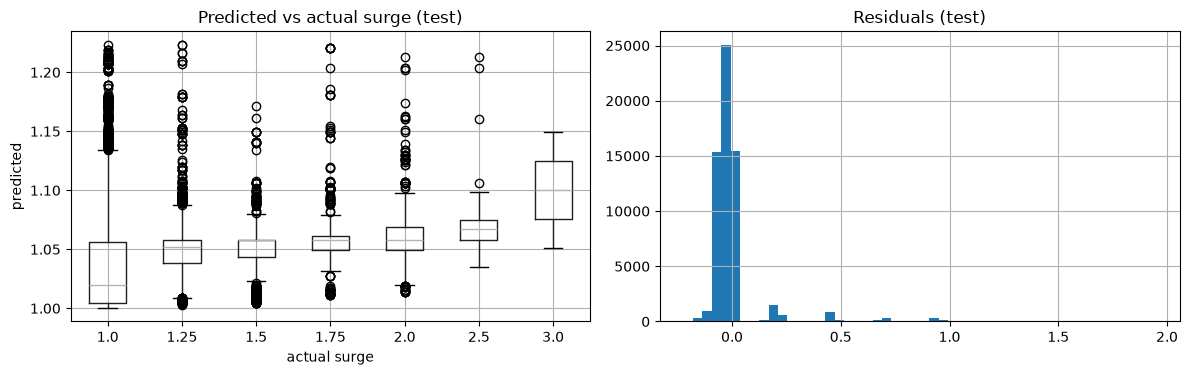

In [12]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
test_view.boxplot(column="predicted", by="actual", ax=axes[0])
axes[0].set_title("Predicted vs actual surge (test)"); axes[0].set_xlabel("actual surge"); axes[0].set_ylabel("predicted")
(y_test - y_pred).hist(bins=50, ax=axes[1]); axes[1].set_title("Residuals (test)")
plt.suptitle(""); plt.tight_layout(); plt.savefig("reports/figures/05_final_evaluation.png", dpi=100); plt.show()

### Feature importance (if the model provides it)

In [13]:
est = best_model.named_steps["model"]
names = best_model.named_steps["preprocessor"].get_feature_names_out()
if hasattr(est, "feature_importances_"):
    imp = pd.Series(est.feature_importances_, index=names).sort_values(ascending=False).head(15)
    display(imp.round(4))
else:
    print("Model has no feature_importances_")

numeric__distance                         0.2900
categorical__name_Shared                  0.1944
categorical__source_Back Bay              0.1015
categorical__source_North End             0.0539
categorical__source_North Station         0.0511
categorical__source_West End              0.0475
categorical__source_Haymarket Square      0.0378
numeric__visibility                       0.0235
categorical__source_Theatre District      0.0234
numeric__cloudCover                       0.0221
categorical__source_South Station         0.0216
numeric__windSpeed                        0.0209
numeric__temperature                      0.0188
categorical__source_Financial District    0.0162
numeric__hour                             0.0136
dtype: float64

## Save the full Pipeline (preprocessor + model)

In [14]:
import os
os.makedirs("models", exist_ok=True)
joblib.dump(best_model, "models/best_model.joblib")

summary = {
    "model": best_name,
    "best_params": {k.replace("model__", ""): v for k, v in best_grid.best_params_.items()},
    "cv_rmse": float(-best_grid.best_score_),
    "test": {k: float(v) for k, v in metrics(y_test, y_pred).items()},
    "baseline_test": {k: float(v) for k, v in metrics(y_test, b_pred).items()},
    "test_surged": {k: float(v) for k, v in metrics(y_test[surged], y_pred[surged]).items() if k != "R2"},
    "baseline_test_surged": {k: float(v) for k, v in metrics(y_test[surged], b_pred[surged]).items() if k != "R2"},
    "feature_columns": list(X_train.columns),
}
with open("reports/final_metrics.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))

{
  "model": "Random Forest",
  "best_params": {
    "max_depth": 12,
    "min_samples_leaf": 200,
    "n_estimators": 100
  },
  "cv_rmse": 0.13168300657459792,
  "test": {
    "MSE": 0.018289427755525847,
    "RMSE": 0.1352384107993208,
    "MAE": 0.0560873927777349,
    "R2": 0.0430374244956917
  },
  "baseline_test": {
    "MSE": 0.019113418651757922,
    "RMSE": 0.1382512880654568,
    "MAE": 0.058964243550539495,
    "R2": -7.646954137618955e-05
  },
  "test_surged": {
    "MSE": 0.23976733417088966,
    "RMSE": 0.4896604274095362,
    "MAE": 0.4087485965762683
  },
  "baseline_test_surged": {
    "MSE": 0.2610045373849508,
    "RMSE": 0.5108860316988034,
    "MAE": 0.4310679583944533
  },
  "feature_columns": [
    "source",
    "destination",
    "name",
    "short_summary",
    "distance",
    "hour",
    "day_of_week",
    "is_weekend",
    "temperature",
    "precipIntensity",
    "humidity",
    "windSpeed",
    "visibility",
    "cloudCover"
  ]
}


## Sanity check - load the saved file and predict raw rows (what the GUI does)

In [15]:
loaded = joblib.load("models/best_model.joblib")
new_data = X_test.head(5)                       # raw, un-encoded, un-scaled rows
prediction = loaded.predict(new_data)
print(prediction)
assert np.allclose(prediction, y_pred[:5]), "loaded model gives different predictions"
assert list(loaded.feature_names_in_) == list(X_train.columns)
print("OK - saved Pipeline predicts from raw features with no external preprocessing")

[1.14408286 1.0182253  1.00993664 1.01807221 1.05775431]
OK - saved Pipeline predicts from raw features with no external preprocessing
